# Recommend products from synthetic purchase histories

Which five products is each customer most likely to purchase in the next 30 days? Train a local Kumo Engine model on generated synthetic relational data, then score newly added records.

Use a Linux notebook kernel with CPU compute and writable local scratch. Complete [Linux deployment setup](https://docs.nvidia.com/sdgm/kumo-engine/get-started-with-kumo-engine/installation/linux-machine-deployment).
This example follows [the product recommendations workflow](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/code-examples/linux-deployment/product-recommendations).


## Install

Install the Engine SDK and the data libraries used by this notebook.


In [ ]:
%pip install -q kumo-engine pandas numpy pyarrow


## Import the local Engine APIs

Use the local Engine graph, query, and trainer APIs in the prepared notebook kernel.


In [1]:
import json
import os
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import pandas as pd
from IPython.display import display
import kumo.engine as kumo
from kumo.engine.trainer.output_config import ModelOutputConfig, PredictionOutputConfig, TrainingTableOutputConfig
from kumoapi.graph import Edge
from kumoapi.jobs import MetadataField, PredictionArtifactType
from kumoapi.model_plan import RunMode, TrainingTableGenerationPlan
from kumoapi.typing import Dtype, Stype


/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Set the example parameters

Scratch defaults to `kumo_scratch` under the current directory; set `KUMO_SCRATCH` to use another writable local directory. Each run gets its own scratch and retained output directories. Times are timezone-naive UTC.
Leave `SMOKE_MODE=False` for the FAST tutorial plan; smoke mode caps training at one epoch and does not measure model quality.


In [2]:
SCRATCH_PARENT = Path(os.environ.get("KUMO_SCRATCH", str(Path.cwd() / "kumo_scratch"))).expanduser().resolve()
OUTPUT_PARENT = Path.cwd() / "kumo_example_runs"
RANDOM_SEED = 42
AS_OF = pd.Timestamp("2025-01-01")
SMOKE_MODE = False
NUM_CLASSES_TO_RETURN = 5

SCRATCH_PARENT.mkdir(parents=True, exist_ok=True)
if not SCRATCH_PARENT.is_dir():
    raise ValueError("KUMO_SCRATCH must point to a writable local directory.")
OUTPUT_PARENT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="synthetic_product_recommendations-", dir=OUTPUT_PARENT))
scratch_dir = Path(mkdtemp(prefix="synthetic_product_recommendations-", dir=SCRATCH_PARENT))
source_dir = run_dir / "source"
output_dir = run_dir / "output"
source_dir.mkdir()
output_dir.mkdir()
kumo.configure(scratch_dir=scratch_dir)
destination = kumo.FileConnector(root_dir=str(output_dir))
print("Retained run:", run_dir)
print("Scratch:", scratch_dir)


Retained run: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_example_runs/synthetic_product_recommendations-uznnnods
Scratch: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_scratch/synthetic_product_recommendations-twtnlf8r


## Generate synthetic example data

Create customers, a product catalog, and timestamped purchases. Each customer favors a category and a few products, with random exploration so future purchases are not deterministic.
Run the next cell to generate the history and a separate batch reserved for scoring. You can skim the generation code; the Kumo workflow starts below.


In [3]:
rng = np.random.default_rng(RANDOM_SEED)
CATEGORIES = ["home", "outdoors", "stationery", "kitchen"]
products = pd.DataFrame({"product_id": np.arange(1, 81, dtype=np.int64),
    "category": np.repeat(CATEGORIES, 20), "price": np.round(rng.uniform(5, 150, 80), 2)})

def make_customers_and_purchases(first_id, count, start, end, first_purchase):
    customers = pd.DataFrame({"customer_id": np.arange(first_id, first_id + count, dtype=np.int64),
        "signup_channel": rng.choice(["web", "store"], count),
        "region": rng.choice(["north", "south", "east", "west"], count)})
    records = []
    days = (pd.Timestamp(end) - pd.Timestamp(start)).days
    for customer_id in customers.customer_id:
        category = rng.choice(CATEGORIES)
        favorites = rng.choice(products.loc[products.category.eq(category), "product_id"], 4, replace=False)
        rate = rng.uniform(0.04, 0.12)
        for day in np.flatnonzero(rng.random(days) < rate):
            product_id = int(rng.choice(favorites if rng.random() < 0.85 else products.product_id))
            records.append((first_purchase + len(records), customer_id, product_id,
                            pd.Timestamp(start) + pd.Timedelta(days=int(day), hours=12), int(rng.integers(1, 4))))
    purchases = pd.DataFrame(records, columns=["purchase_id", "customer_id", "product_id", "purchased_at", "quantity"])
    return customers, purchases

customers, purchases = make_customers_and_purchases(1, 600, "2024-01-01", AS_OF, 1)
new_customers, new_purchases = make_customers_and_purchases(
    601, 40, AS_OF - pd.Timedelta(days=60), AS_OF, int(purchases.purchase_id.max()) + 1)
assert purchases.purchase_id.is_unique
assert purchases.customer_id.isin(customers.customer_id).all()
assert purchases.product_id.isin(products.product_id).all()
assert purchases.purchased_at.lt(AS_OF).all() and new_purchases.purchased_at.lt(AS_OF).all()
for name, frame in {"customers": customers, "products": products, "purchases": purchases}.items():
    (source_dir / name).mkdir()
    frame.to_parquet(source_dir / name / "history.parquet", index=False)
display(purchases.head())
print("Customers:", len(customers), "Products:", len(products), "Purchases:", len(purchases))


/tmp/ipykernel_1356096/282149143.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(start) + pd.Timedelta(days=int(day), hours=12), int(rng.integers(1, 4))))


/tmp/ipykernel_1356096/282149143.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  601, 40, AS_OF - pd.Timedelta(days=60), AS_OF, int(purchases.purchase_id.max()) + 1)


,purchase_id,customer_id,product_id,purchased_at,quantity
0,1,1,2,2024-02-07 12:00:00,1
1,2,1,4,2024-02-10 12:00:00,1
2,3,1,2,2024-02-12 12:00:00,3
3,4,1,2,2024-02-16 12:00:00,2
4,5,1,2,2024-02-19 12:00:00,3


Customers: 600 Products: 80 Purchases: 17227


## Build the graph

Connect each purchase directly to both its customer and product. The product foreign key makes the target a recommendation over product entities.
See [tables and relationships](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs).


In [4]:
files = kumo.FileConnector(root_dir=str(source_dir))
customer_table = kumo.Table.from_source_table(files["customers"], primary_key="customer_id")
for column in ("signup_channel", "region"):
    customer_table = customer_table.with_column(column, stype=Stype.categorical)
product_table = (kumo.Table.from_source_table(files["products"], primary_key="product_id")
    .with_column("category", stype=Stype.categorical).with_column("price", stype=Stype.numerical))
purchase_table = (kumo.Table.from_source_table(files["purchases"], primary_key="purchase_id", time_column="purchased_at")
    .with_column("purchased_at", dtype=Dtype.date)
    .with_column("customer_id", stype=Stype.ID).with_column("product_id", stype=Stype.ID)
    .with_column("quantity", stype=Stype.numerical))
graph = kumo.Graph(tables={"customers": customer_table, "products": product_table, "purchases": purchase_table},
    edges=[Edge("purchases", "customer_id", "customers"), Edge("purchases", "product_id", "products")])
graph.validate()


## Inspect the graph

Inspect the actual graph's tables and relationships before training with [graph visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).
The table also lists each declared foreign-key relationship.


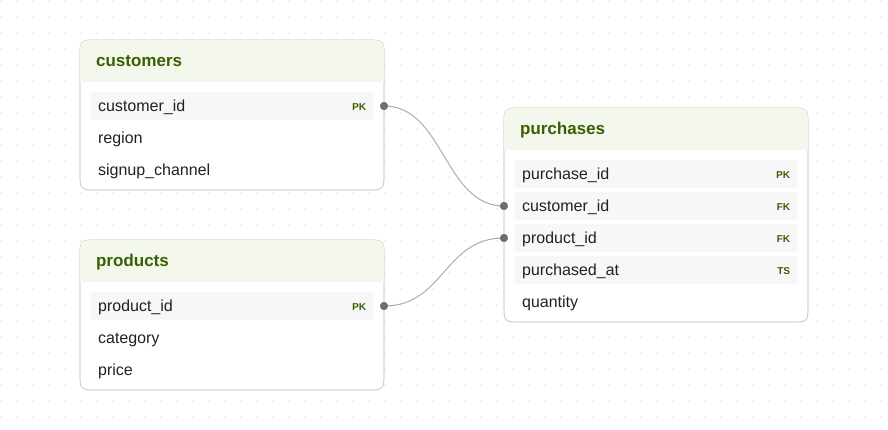

,source,foreign_key,destination
0,purchases,customer_id,customers
1,purchases,product_id,products


In [5]:
display(graph.visualize(show_cols=True))
display(pd.DataFrame([{"source": edge.src_table, "foreign_key": edge.fkey,
                       "destination": edge.dst_table} for edge in graph.edges]))


## Materialize the graph

Build a snapshot of the historical source files for training.


In [6]:
snapshot = graph.snapshot()
print("Training snapshot:", snapshot.id)


/tmp/ipykernel_1356096/3370640593.py:1: UserWarning: The kumo.engine scratch directory /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_scratch/synthetic_product_recommendations-twtnlf8r is on Amazon EBS. Graph sampling and training-table generation read it randomly and run much slower there; local NVMe is recommended.
  snapshot = graph.snapshot()


ingest: table started phase="encode" table=customers


ingest: table producers complete phase="encode" table=customers rows=600 elapsed_ms=2


ingest: Ingestion stage progress phase=Encode table=customers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=products


ingest: table producers complete phase="encode" table=products rows=80 elapsed_ms=0


... (16 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 17907 nodes, 68908 edges


Training snapshot: 88dc0967b802bb4e85fc2c440ec5b01fec23f7e8be8cdacd3cf034275d589b18@6fa3c0cf588f77ac


## Define the prediction task

Collect products purchased in `(anchor, anchor + 30 days]`. The target is a set of product IDs, and `RANK TOP 5` asks for five candidates. Repeat purchases are allowed in this replenishment example.
Validate the [predictive query](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/predictive-queries) before generating labels.


In [7]:
QUERY = 'PREDICT LIST_DISTINCT(purchases.product_id, 0, 30, days) RANK TOP 5 FOR EACH customers.customer_id'
query = kumo.PredictiveQuery(graph, QUERY)
query.validate()
assert query.get_task_type() == 'temporal_link_prediction'
print(QUERY)
print("Task:", query.get_task_type())


PREDICT LIST_DISTINCT(purchases.product_id, 0, 30, days) RANK TOP 5 FOR EACH customers.customer_id
Task: temporal_link_prediction


## Generate training rows and inspect the splits

Use an approximate chronological 70/15/15 split so validation and test follow training. Use the most recent 300 days of history, with anchors 30 days apart. ApproxDateOffsetSplit separates label windows across splits; the latest anchor leaves 30 days of observed outcomes. Inspect the actual split sizes below.
Export the [training table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training-tables) to inspect its actual splits: `0` is training, `1` validation, and `2` test. `ENTITY1` identifies the entity, `TIMESTAMP` its anchor, and `TARGET1` the outcome.


In [8]:
generation_plan = TrainingTableGenerationPlan(
    split="ApproxDateOffsetSplit([0.7, 0.15, 0.15])",
train_start_offset=300, train_end_offset=0, timeframe_step=30,
)
training_table = query.generate_training_table(snapshot, plan=generation_plan)
training_table.export(TrainingTableOutputConfig(connector=destination, table_name="training_rows/"))
training_rows = pd.read_parquet(output_dir / "training_rows")
display(training_rows.head(8))
display(training_rows.groupby("SPLIT").agg(rows=("ENTITY1", "size"),
    first_anchor=("TIMESTAMP", "min"), last_anchor=("TIMESTAMP", "max")))
assert set(training_rows.SPLIT) == {0, 1, 2}


,ENTITY1,TIMESTAMP,TARGET1,__kumo_internal_frequency_column__,SPLIT
0,1,2024-03-06 12:00:00,"[68, 4, 12, 42]","[1, 1, 2, 1]",0
1,1,2024-04-05 12:00:00,"[77, 2, 4]","[1, 2, 1]",0
2,1,2024-05-05 12:00:00,"[12, 7, 2]","[1, 1, 2]",0
3,1,2024-07-04 12:00:00,[12],[1],0
4,1,2024-08-03 12:00:00,[4],[2],0
5,1,2024-10-02 12:00:00,[4],[2],0
6,2,2024-03-06 12:00:00,"[23, 21, 38]","[1, 1, 1]",0
7,2,2024-04-05 12:00:00,"[24, 23, 21]","[1, 2, 1]",0


,rows,first_anchor,last_anchor
SPLIT,,,
0,4251,2024-03-06 12:00:00,2024-10-02 12:00:00
1,526,2024-11-01 12:00:00,2024-11-01 12:00:00
2,538,2024-12-01 12:00:00,2024-12-01 12:00:00


## Configure the model

Start from the supported [FAST plan](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/training). Select by MAP@5 to match the five returned product recommendations.
Disable refitting to keep validation and test separate from the fitted training population.


In [9]:
plan = query.suggest_model_plan(snapshot, run_mode=RunMode.FAST)
plan.training_job.refit_trainval = False
plan.training_job.refit_full = False

plan.training_job.tune_metric = "map@5"
if SMOKE_MODE:
    plan.training_job.num_experiments = 1
    plan.optimization.max_epochs = 1
    print("Smoke mode: pipeline check only")
(output_dir / "model_plan.json").write_text(json.dumps(plan.as_json(), indent=2) + "\n")
print("Tuning metric:", plan.training_job.tune_metric)
print("Maximum epochs:", plan.optimization.max_epochs)


Tuning metric: map@5
Maximum epochs: 8


## Train and retain the model

Fit on the generated training rows and export the complete model bundle for reuse.


In [10]:
trainer = kumo.Trainer(plan, accelerator="cpu")
fit_result = trainer.fit(training_table, snapshot=snapshot,
    export_config=ModelOutputConfig(connector=destination, path="model"))
print("Saved model:", output_dir / "model")


[I 2026-11-09 18:59:47,850] A new study created in memory with name: no-name-4d79de23-efe8-419d-858a-9babee14c665


GPU available: False, used: False


TPU available: False, using: 0 TPU cores



   | Name               | Type                     | Params | Mode  | FLOPs
---------------------------------------------------------------------------------
0  | metric_store       | MetricStore              | 0      | train | 0    
1  | encoder            | HeteroTensorFrameEncoder | 21.1 K | train | 0    
2  | model              | HeteroGNN                | 494 K  | train | 0    
3  | head               | LinkPredHead             | 4.3 K  | train | 0    
4  | locality_score     | LocalityScore            | 0      | train | 0    
5  | lhs_projector      | Projector                | 4.1 K  | train | 0    
6  | identity_awareness | Embedding                | 128    | train | 0    
7  | rhs_projector      | Linear                   | 4.2 K  | train | 0    
8  | rhs_embedding      | RHSEmbedding             | 2.6 K  | train | 0    
9  | lin_offset_idgnn   | Linear                   | 129    | train | 0    
10 | lin_offset_embgnn  | Linear                   | 129    | train | 0    
-----

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (296 outputs left out)

Testing DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:02<00:00,  0.83it/s]

Testing DataLoader 0: 100%|██████████| 2/2 [00:02<00:00,  0.83it/s]

Saved model: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_example_runs/synthetic_product_recommendations-uznnnods/output/model


## Evaluate

**Synthetic-data metrics - demonstration only.** Review the fit's metrics to check that the workflow learned from the generated patterns. MAP@5 rewards relevant products near the top of each customer’s five recommendations; recall@5 measures how many of their future products were retrieved.
These are the fit's reported metrics; choose settings using validation and reserve test results for final assessment.


In [11]:
print("Synthetic-data metrics — demonstration only")
display(pd.Series(fit_result.metrics, name="value").rename_axis("metric").to_frame())
(output_dir / "metrics.json").write_text(json.dumps(fit_result.metrics, indent=2, default=float) + "\n")


Synthetic-data metrics — demonstration only


,value
metric,
val_recall@1,0.215304
val_map@1,0.465779
val_f1@10,0.287761
val_map@10,0.567777
val_f1@1,0.278970
val_recall@100,1.000000
val_precision@10,0.180989
val_recall@10,0.847560
val_f1@100,0.042344


1914

## Batch predictions

Add 40 new customers and their observed 60-day purchase histories. They use the existing product catalog, and no future purchases are included. Write the new rows as additional Parquet parts in the existing table directories. A new snapshot reads those parts while the training snapshot remains unchanged.


In [12]:
assert set(new_customers.customer_id).isdisjoint(customers.customer_id)
new_customers.to_parquet(source_dir / "customers" / "new.parquet", index=False)
new_purchases.to_parquet(source_dir / "purchases" / "new.parquet", index=False)
scoring_population = pd.DataFrame({"ENTITY1": new_customers.customer_id, "TIMESTAMP": AS_OF})
assert not any(column.startswith("TARGET") for column in scoring_population)
assert len(scoring_population) == 40 and not scoring_population.duplicated(["ENTITY1", "TIMESTAMP"]).any()
scoring_population.to_parquet(source_dir / "scoring_population.parquet", index=False)
scoring_snapshot = graph.snapshot()
assert scoring_snapshot.id != snapshot.id
display(scoring_population.head())


ingest: table started phase="encode" table=customers


ingest: table producers complete phase="encode" table=customers rows=640 elapsed_ms=2


ingest: Ingestion stage progress phase=Encode table=customers shard=None progress_pct=100 current=1 total=1


ingest: table started phase="encode" table=products


ingest: table producers complete phase="encode" table=products rows=80 elapsed_ms=0


ingest: Ingestion stage progress phase=Encode table=products shard=None progress_pct=100 current=1 total=1


... (15 outputs left out)

ingest: finalize stage complete stage="finalize" elapsed_ms=0 elapsed=0ms


diskgraph ingest succeeded after 1 attempt(s) at 5 threads


diskgraph ingest completed: 3 node tables, 4 edge relations, 18128 nodes, 69632 edges


,ENTITY1,TIMESTAMP
0,601,2025-01-01
1,602,2025-01-01
2,603,2025-01-01
3,604,2025-01-01
4,605,2025-01-01


### Prepare the scoring population

Use a [custom prediction table](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/making-predictions) containing only the 40 new entity IDs and their anchor times. This keeps historical training entities out of the scoring batch.


In [13]:
prediction_table = kumo.PredictionTable.from_source_table(
    files["scoring_population"], pq=query, snapshot=scoring_snapshot, plan=generation_plan)
generated_population = pd.read_parquet(prediction_table.table_path)
assert set(generated_population.ENTITY1) == set(scoring_population.ENTITY1)
assert len(generated_population) == len(scoring_population)
display(generated_population.head())


,ENTITY1,TIMESTAMP
0,601,2025-01-01
1,602,2025-01-01
2,603,2025-01-01
3,604,2025-01-01
4,605,2025-01-01


### Score the new records

Run the trained model on the new snapshot and save predictions, including anchor timestamps, as Parquet.


In [14]:
prediction_result = trainer.predict(
    prediction_table, snapshot=scoring_snapshot,
    num_classes_to_return=NUM_CLASSES_TO_RETURN,
    output_config=PredictionOutputConfig(connector=destination,
        artifact_type=PredictionArtifactType.PREDICTIONS, table_name="predictions.parquet",
        extra_fields=[MetadataField.ANCHOR_TIMESTAMP]),
)
scores = prediction_result.frame


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


Restoring states from the checkpoint path at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_scratch/synthetic_product_recommendations-twtnlf8r/trainers/156015f533024c1087bbc2baf954b22e/runs/156015f533024c1087bbc2baf954b22e-predict-fd604d7488db4747bb035d9cd58c38ee/model_bundle/model/checkpoint/step=0.ckpt


Loaded model weights from the checkpoint at file:///tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_scratch/synthetic_product_recommendations-twtnlf8r/trainers/156015f533024c1087bbc2baf954b22e/runs/156015f533024c1087bbc2baf954b22e-predict-fd604d7488db4747bb035d9cd58c38ee/model_bundle/model/checkpoint/step=0.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 21.76it/s]

Predicting DataLoader 0: 100%|██████████| 2/2 [00:00<00:00, 21.30it/s]

### Inspect and verify the results

`ENTITY` is the new record ID and `ANCHOR_TIMESTAMP` its scoring time. Expect five rows per customer. `CLASS` is a product ID; `SCORE` orders candidates and is not a calibrated probability. Join product details by ID, then sort scores to assign ranks. Verify IDs and times together, not row order.


In [15]:
expected = scoring_population.rename(columns={"ENTITY1": "ENTITY", "TIMESTAMP": "ANCHOR_TIMESTAMP"})
expected["ANCHOR_TIMESTAMP"] = pd.to_datetime(expected.ANCHOR_TIMESTAMP)
scores["ANCHOR_TIMESTAMP"] = pd.to_datetime(scores.ANCHOR_TIMESTAMP)

assert not scores.duplicated(["ENTITY", "ANCHOR_TIMESTAMP", "CLASS"]).any()
keys = scores[["ENTITY", "ANCHOR_TIMESTAMP"]].drop_duplicates()
aligned = expected.merge(keys, how="outer", validate="one_to_one", indicator=True)
assert aligned._merge.eq("both").all()
assert scores.groupby(["ENTITY", "ANCHOR_TIMESTAMP"]).size().eq(NUM_CLASSES_TO_RETURN).all()
assert np.isfinite(scores.SCORE.to_numpy()).all()

assert scores.CLASS.isin(products.product_id).all()
recommendations = scores.merge(products, left_on="CLASS", right_on="product_id", validate="many_to_one")
recommendations = recommendations.sort_values(["ENTITY", "ANCHOR_TIMESTAMP", "SCORE"], ascending=[True, True, False])
recommendations["rank"] = recommendations.groupby(["ENTITY", "ANCHOR_TIMESTAMP"]).cumcount() + 1
display(recommendations.head(10))
recommendations.to_parquet(output_dir / "recommendations_with_products.parquet", index=False)
pd.testing.assert_frame_equal(scores, pd.read_parquet(output_dir / "predictions.parquet"))
print("Saved predictions:", output_dir / "predictions.parquet")


,ENTITY,CLASS,SCORE,ANCHOR_TIMESTAMP,product_id,category,price,rank
0,601,49,7.435179,2025-01-01,49,stationery,103.96,1
1,601,44,7.435059,2025-01-01,44,stationery,50.29,2
2,601,51,7.435000,2025-01-01,51,stationery,33.99,3
3,601,20,6.270861,2025-01-01,20,home,96.59,4
4,601,46,6.266989,2025-01-01,46,stationery,121.69,5
100,602,46,3.784036,2025-01-01,46,stationery,121.69,1
101,602,54,3.139584,2025-01-01,54,stationery,101.40,2
102,602,3,3.082294,2025-01-01,3,home,129.50,3
103,602,35,2.869050,2025-01-01,35,outdoors,73.09,4
104,602,55,2.780129,2025-01-01,55,stationery,107.25,5


Saved predictions: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_example_runs/synthetic_product_recommendations-uznnnods/output/predictions.parquet


## Retain and reuse

Reload the complete trusted model bundle without fitting again. Keep the source tables and compatible graph schema alongside the bundle; the model does not contain graph data.
A later process must configure scratch, rebuild the graph and snapshot, and prepare its scoring table. See [publish and retrieve models](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/train-a-model/publish-and-retrieve-models).


In [16]:
reloaded_trainer = kumo.Trainer.load(output_dir / "model", accelerator="cpu")
print("Reloaded model from:", output_dir / "model")
print("Retain this run directory:", run_dir)


Reloaded model from: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_example_runs/synthetic_product_recommendations-uznnnods/output/model
Retain this run directory: /tmp/kumo-notebook-runs/local_kumo_engine_synthetic_product_recommendations/20261109T185938Z/kumo_example_runs/synthetic_product_recommendations-uznnnods


## Cleanup

Keep the generated inputs, model, and predictions under `run_dir`. After scoring and reload checks, optionally remove only this run's scratch directory; rebuild snapshots before further prediction.


In [17]:
import shutil

REMOVE_RUN_SCRATCH = False
if REMOVE_RUN_SCRATCH:
    shutil.rmtree(scratch_dir)
    print("Removed run scratch:", scratch_dir)
